# 00 · Exploración de los datos: ¿de qué señales estamos hablando?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jafcn09/examenfinal_redes_uniingenieria/blob/main/notebooks/00_exploracion_datos.ipynb)

**MIA-203 Redes Neuronales y Aprendizaje Profundo · UNI · Grupo 6**

Este notebook explica con imágenes el problema y los datos **antes** de entrenar cualquier red. Responde, en orden:

1. ¿Qué es un rodamiento y dónde se daña?
2. ¿Cómo se obtuvieron los datos (banco de ensayo CWRU)?
3. ¿Cómo se ve la vibración de un rodamiento sano y de uno dañado?
4. ¿Qué dice la física? Frecuencias de falla (BPFO, BPFI, BSF) y espectro de envolvente.
5. ¿Qué problemas tenían los datos y cómo se corrigieron?
6. ¿Cómo se convierten las señales en ejemplos para la red (ventanas, particiones, desbalance)?
7. ¿Qué "ve" cada modelo (CNN 1D, CNN 2D, AST)? ¿Y con ruido?

> **El problema real:** los rodamientos causan entre el 41 % y el 44 % de las fallas de los motores eléctricos (encuestas de EPRI e IEEE). Si se detecta el daño a tiempo a partir de la vibración, se puede programar el cambio antes de que la máquina se detenga (*mantenimiento predictivo*).

In [1]:

import os, sys, subprocess
from pathlib import Path
REPO_URL = "https://github.com/jafcn09/examenfinal_redes_uniingenieria.git"
if not Path("src/cwru_dl").exists():
    if Path("../src/cwru_dl").exists():
        os.chdir("..")
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, "examenfinal_redes_uniingenieria"], check=True)
        os.chdir("examenfinal_redes_uniingenieria")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
sys.path.insert(0, "src")

import numpy as np, pandas as pd, torch, torchaudio
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch, FancyArrowPatch, Rectangle
from scipy.signal import welch, hilbert, resample_poly

from cwru_dl import CLASSES, load_config
from cwru_dl.config import BEARING, FOLDERS
from cwru_dl.data import download_cwru, load_signal, load_meta, make_windows, zscore, fault_freqs, build_split
from cwru_dl.augment import add_noise
from cwru_dl.models import STFTFrontend

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
cfg = load_config("configs/full.yaml", profile="full")
download_cwru(cfg.root)                      # ~190 MB la primera vez
FS = cfg.fs                                  # 12 kHz
COLORS = {"Normal": "tab:green", "B": "tab:blue", "IR": "tab:red", "OR": "tab:orange"}
def color(c): return COLORS["Normal"] if c == "Normal" else COLORS[c[:2] if c[:2] in COLORS else c[0]]
print("datos en", cfg.root.resolve())

datos en /content/examenfinal_redes_uniingenieria/data/CWRU


## 1. ¿Qué es un rodamiento y dónde se daña?

Un rodamiento de bolas tiene una **pista externa** (fija a la carcasa), una **pista interna** (gira con el eje) y **bolas** que ruedan entre ambas. En el banco de CWRU el rodamiento es un **SKF 6205** con 9 bolas.
Se perforaron defectos pequeños (0.007, 0.014 y 0.021 pulgadas = 0.18, 0.36 y 0.53 mm) por electroerosión en tres lugares. Esas son nuestras clases de falla:

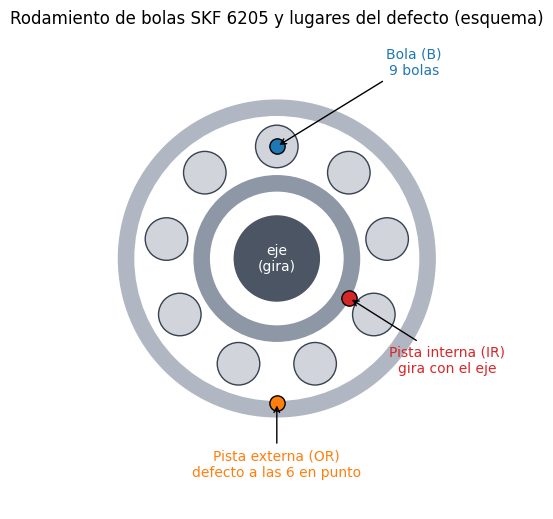

In [2]:
fig, ax = plt.subplots(figsize=(6.2, 6.2))
ax.set_aspect("equal"); ax.axis("off")
R_out, R_in, r_ball, R_pitch = 3.0, 1.75, 0.45, 2.37
ax.add_patch(Circle((0, 0), R_out + 0.35, color="#b0b7c3"))           # pista externa
ax.add_patch(Circle((0, 0), R_out, color="white"))
ax.add_patch(Circle((0, 0), R_in, color="#8d97a6"))                    # pista interna
ax.add_patch(Circle((0, 0), R_in - 0.35, color="white"))
ax.add_patch(Circle((0, 0), 0.9, color="#4b5563"))                     # eje
for k in range(9):                                                      # 9 bolas
    a = 2 * np.pi * k / 9 + np.pi / 2
    ax.add_patch(Circle((R_pitch * np.cos(a), R_pitch * np.sin(a)), r_ball, color="#d1d5db", ec="#374151"))
# defectos
ax.plot([0], [-(R_out + 0.05)], marker="o", ms=11, color=COLORS["OR"], mec="k")                   # OR a las 6
ax.plot([R_in * np.cos(-0.5)], [R_in * np.sin(-0.5)], marker="o", ms=11, color=COLORS["IR"], mec="k")
bx, by = R_pitch * np.cos(np.pi / 2), R_pitch * np.sin(np.pi / 2)
ax.plot([bx], [by], marker="o", ms=11, color=COLORS["B"], mec="k")
kw = dict(fontsize=10, ha="center")
ax.annotate("Pista externa (OR)\ndefecto a las 6 en punto", (0, -R_out - 0.05), (0, -4.6), arrowprops=dict(arrowstyle="->"), color=COLORS["OR"], **kw)
ax.annotate("Pista interna (IR)\ngira con el eje", (R_in * np.cos(-0.5), R_in * np.sin(-0.5)), (3.6, -2.4), arrowprops=dict(arrowstyle="->"), color=COLORS["IR"], **kw)
ax.annotate("Bola (B)\n9 bolas", (bx, by), (2.9, 3.9), arrowprops=dict(arrowstyle="->"), color=COLORS["B"], **kw)
ax.text(0, 0, "eje\n(gira)", color="white", **kw, va="center")
ax.set_xlim(-5, 5); ax.set_ylim(-5.3, 4.8)
ax.set_title("Rodamiento de bolas SKF 6205 y lugares del defecto (esquema)")
plt.show()

Cada vez que una bola pasa sobre el defecto se produce un **golpe** (impacto) que excita las resonancias de la máquina. Esos golpes se repiten a un ritmo que depende de **dónde** está el defecto: esa es la "huella" que la red tiene que aprender.

## 2. El banco de ensayo de CWRU

Un motor eléctrico de 2 HP mueve un eje con un **transductor de torque** y un **dinamómetro** que aplica carga (0, 1, 2 o 3 HP). Un **acelerómetro** en la carcasa del lado del accionamiento (*drive end*) mide la vibración 12 000 veces por segundo (12 kHz).

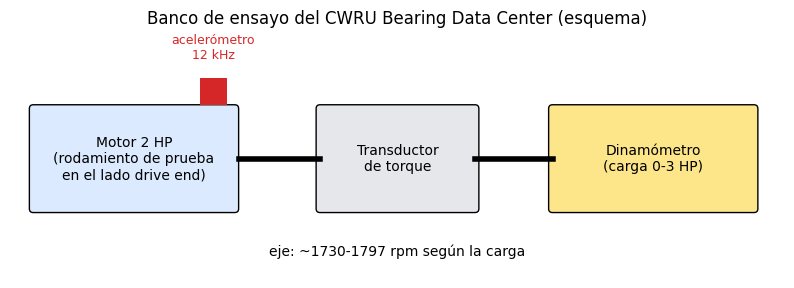

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.2)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 3.2)
def box(x, w, txt, fc):
    ax.add_patch(FancyBboxPatch((x, 0.9), w, 1.3, boxstyle="round,pad=0.05", fc=fc, ec="k")); ax.text(x + w / 2, 1.55, txt, ha="center", va="center")
box(0.3, 2.6, "Motor 2 HP\n(rodamiento de prueba\nen el lado drive end)", "#dbeafe")
box(4.0, 2.0, "Transductor\nde torque", "#e5e7eb")
box(7.0, 2.6, "Dinamómetro\n(carga 0-3 HP)", "#fde68a")
ax.plot([2.95, 4.0], [1.55, 1.55], "k", lw=4); ax.plot([6.0, 7.0], [1.55, 1.55], "k", lw=4)
ax.add_patch(Rectangle((2.45, 2.25), 0.35, 0.35, fc="tab:red")); ax.text(2.62, 2.85, "acelerómetro\n12 kHz", ha="center", fontsize=9, color="tab:red")
ax.text(5, 0.3, "eje: ~1730-1797 rpm según la carga", ha="center")
ax.set_title("Banco de ensayo del CWRU Bearing Data Center (esquema)"); plt.show()

In [4]:
meta = load_meta(cfg)
print("40 archivos = 10 clases x 4 cargas. Muestras por archivo (Normal ya remuestreada de 48 a 12 kHz):")
tabla = meta.pivot(index="clase", columns="carga_HP", values="muestras").loc[CLASSES]
display(tabla)
print("rpm por carga:", meta.groupby("carga_HP").rpm.median().round(0).to_dict())
print(f"Cada archivo dura ~{tabla.values.mean() / FS:.1f} s")

40 archivos = 10 clases x 4 cargas. Muestras por archivo (Normal ya remuestreada de 48 a 12 kHz):


carga_HP,0,1,2,3
clase,,,,
Normal,60985,120976,121266,121411
B007,122571,121410,121556,121556
B014,121846,122136,121991,122136
B021,121991,121701,122136,122136
IR007,121265,121991,122136,122917
IR014,121846,121846,121846,121701
IR021,122136,121556,121846,121991
OR007,121991,122426,121410,122571
OR014,121846,122136,121846,121991


rpm por carga: {0: 1796.0, 1: 1772.0, 2: 1750.0, 3: 1724.0}
Cada archivo dura ~10.0 s


## 3. ¿Cómo se ve la vibración?

Primeros 0.1 s (1 200 muestras) de cada clase con carga 0 HP. Fíjate en la **escala del eje vertical**: las fallas de pista (IR, OR) vibran mucho más fuerte que el rodamiento sano y muestran **picos repetidos**.

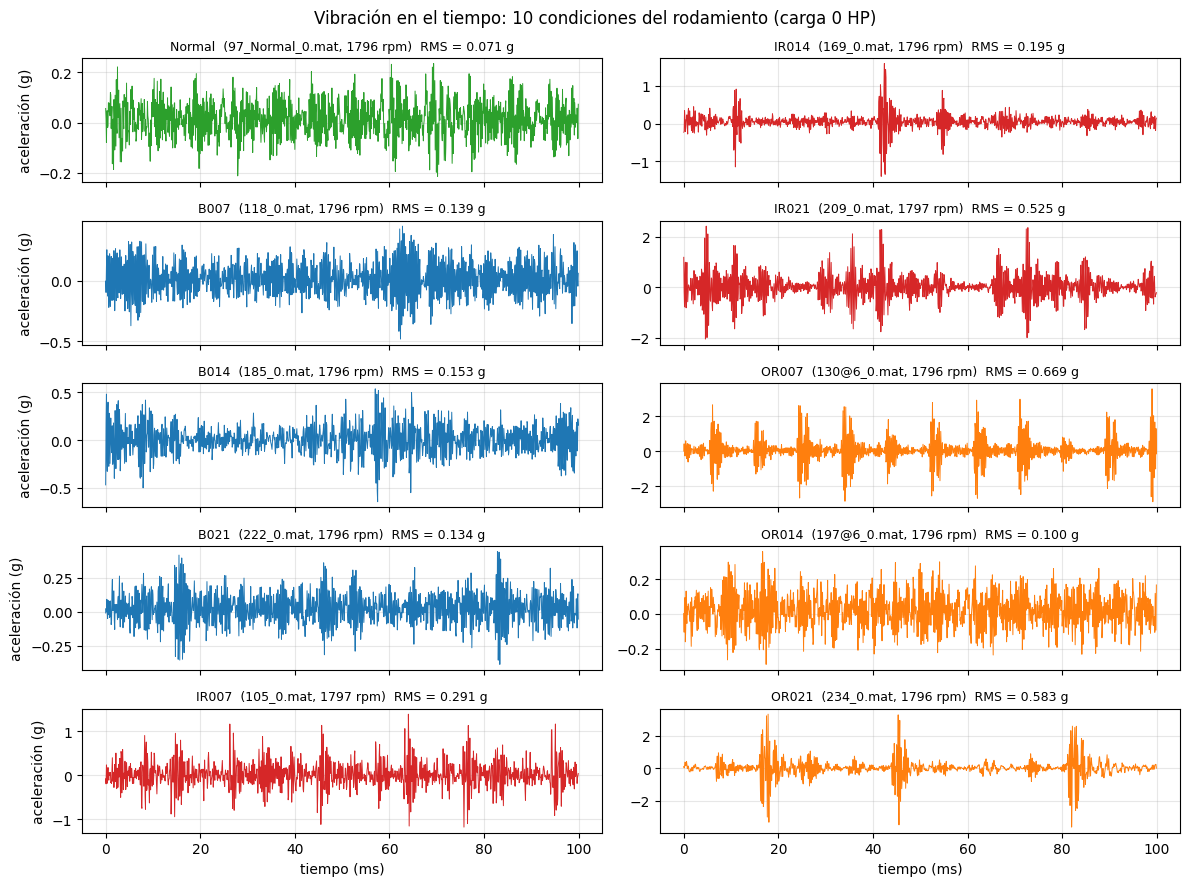

In [5]:
fig, axes = plt.subplots(5, 2, figsize=(12, 9), sharex=True)
n = int(0.1 * FS); t = np.arange(n) / FS * 1000
for ax, c in zip(axes.T.ravel(), CLASSES):
    x, rpm, name = load_signal(cfg, c, 0)
    ax.plot(t, x[:n], color=color(c), lw=0.7)
    ax.set_title(f"{c}  ({name}, {rpm:.0f} rpm)  RMS = {x.std():.3f} g", fontsize=9)
for ax in axes[-1]: ax.set_xlabel("tiempo (ms)")
for ax in axes[:, 0]: ax.set_ylabel("aceleración (g)")
plt.suptitle("Vibración en el tiempo: 10 condiciones del rodamiento (carga 0 HP)"); plt.tight_layout(); plt.show()

### Los golpes del defecto

Ampliamos una falla grave de pista externa (OR021). Las líneas verticales están separadas por **1/BPFO**, el tiempo teórico entre dos bolas que pasan sobre el defecto. Los impactos caen sobre ellas: **la física predice el ritmo de los golpes**.

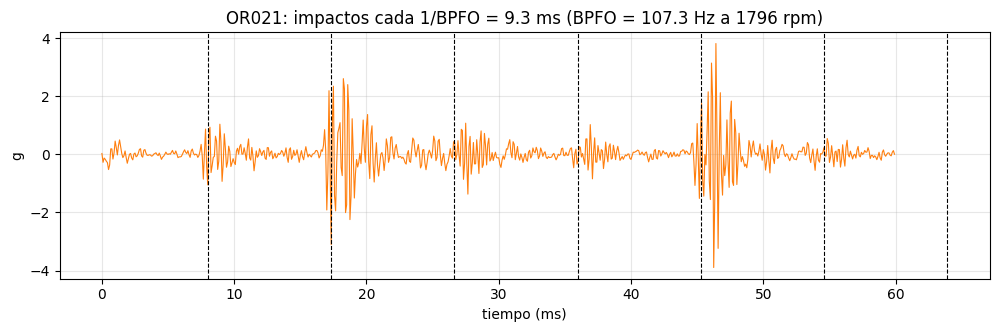

In [6]:
x, rpm, _ = load_signal(cfg, "OR021", 0)
ff = fault_freqs(rpm); T_bpfo = 1 / ff["BPFO"]
seg = x[2000:2000 + int(0.06 * FS)]; t = np.arange(len(seg)) / FS * 1000
t0 = t[np.argmax(np.abs(seg[: int(T_bpfo * FS)]))]
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(t, seg, color=COLORS["OR"], lw=0.8)
for k in range(int(t[-1] / (T_bpfo * 1000)) + 1):
    ax.axvline(t0 + k * T_bpfo * 1000, color="k", ls="--", lw=0.8)
ax.set_xlabel("tiempo (ms)"); ax.set_ylabel("g")
ax.set_title(f"OR021: impactos cada 1/BPFO = {T_bpfo*1000:.1f} ms (BPFO = {ff['BPFO']:.1f} Hz a {rpm:.0f} rpm)")
plt.show()

## 4. Lo que dice la física: frecuencias de falla

Con la geometría del rodamiento (9 bolas, diámetro de bola *d*, diámetro primitivo *D*) y la frecuencia de giro $f_r = \text{rpm}/60$:

$$\text{BPFO} = \tfrac{N_b}{2} f_r \left(1-\tfrac{d}{D}\cos\phi\right)=3.585\,f_r \qquad \text{BPFI} = \tfrac{N_b}{2} f_r \left(1+\tfrac{d}{D}\cos\phi\right)=5.415\,f_r \qquad \text{BSF}=2.357\,f_r$$

- **BPFO** (*ball pass frequency outer*): golpes por segundo cuando el defecto está en la pista externa.
- **BPFI** (*inner*): en la pista interna (más golpes porque la pista interna gira contra las bolas).
- **BSF** (*ball spin*): giro de la bola sobre sí misma, para defectos en la bola.

In [7]:
rows = []
for load, g in meta.groupby("carga_HP"):
    r = g.rpm.median(); f = fault_freqs(r)
    rows.append({"carga (HP)": load, "rpm": round(r), "f_r (Hz)": round(r / 60, 1), **{k: round(v, 1) for k, v in f.items() if k != "FTF"}})
display(pd.DataFrame(rows).set_index("carga (HP)"))
print("Ojo: con 3 HP (test) las frecuencias son ~4 % menores que con 0 HP: el modelo debe generalizar a ese corrimiento.")

,rpm,f_r (Hz),BPFI,BPFO,BSF
carga (HP),,,,,
0,1796,29.9,162.1,107.3,70.5
1,1772,29.5,159.9,105.9,69.6
2,1750,29.2,157.9,104.5,68.7
3,1724,28.7,155.6,103.0,67.7


Ojo: con 3 HP (test) las frecuencias son ~4 % menores que con 0 HP: el modelo debe generalizar a ese corrimiento.


### Espectro de envolvente: la huella de cada falla

Los golpes son cortos y de alta frecuencia, así que en el espectro normal se pierden. El truco clásico es tomar la **envolvente** de la señal (transformada de Hilbert) y ver su espectro: aparecen picos justo en BPFO, BPFI o BSF y sus armónicos.

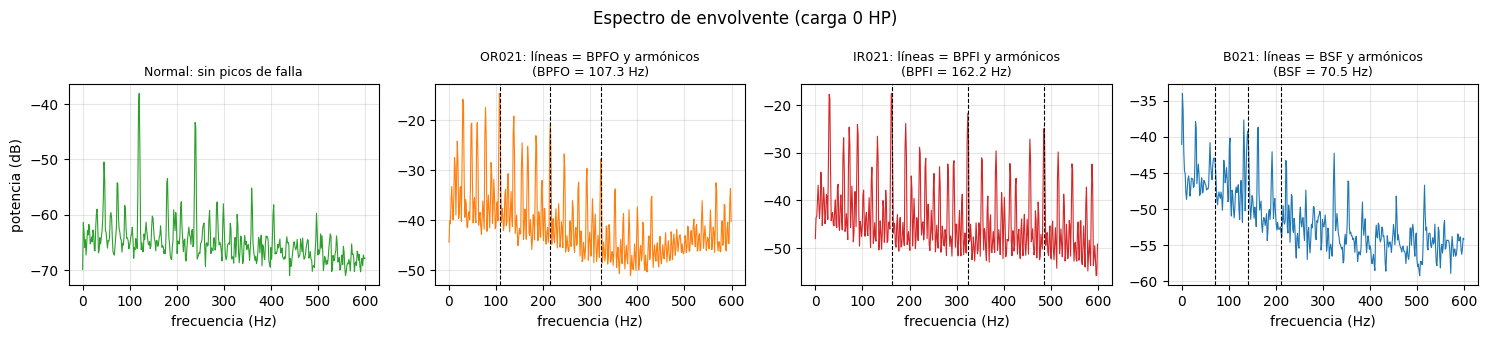

In [8]:
def env_spec(x, fs=FS):
    e = np.abs(hilbert(x - x.mean())); f, p = welch(e - e.mean(), fs=fs, nperseg=8192); return f, p
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=False)
for ax, c, key in zip(axes, ["Normal", "OR021", "IR021", "B021"], [None, "BPFO", "BPFI", "BSF"]):
    x, rpm, _ = load_signal(cfg, c, 0); f, p = env_spec(x); m = f < 600
    ax.plot(f[m], 10 * np.log10(p[m] + 1e-12), color=color(c), lw=0.8)
    if key:
        f0 = fault_freqs(rpm)[key]
        for h in (1, 2, 3):
            ax.axvline(h * f0, color="k", ls="--", lw=0.8)
        ax.set_title(f"{c}: líneas = {key} y armónicos\n({key} = {f0:.1f} Hz)", fontsize=9)
    else:
        ax.set_title("Normal: sin picos de falla", fontsize=9)
    ax.set_xlabel("frecuencia (Hz)")
axes[0].set_ylabel("potencia (dB)")
plt.suptitle("Espectro de envolvente (carga 0 HP)"); plt.tight_layout(); plt.show()

Las fallas de pista muestran picos claros. Las de **bola** son las más difíciles: el pico de BSF es débil o no aparece (está documentado en Smith y Randall, 2015). Esperamos que la red también se confunda más con las clases B.

## 5. Dos problemas de los datos (y su corrección)

**(a) La clase Normal estaba grabada a 48 kHz, no a 12 kHz.** Si se lee como 12 kHz, todas sus frecuencias aparecen 4 veces más bajas. La prueba: las líneas que comparten todas las grabaciones del banco (por ejemplo 159.5, 360 y 533.5 Hz) solo coinciden si se lee a 48 kHz. Sin corregirlo, la red podría reconocer "Normal" por ese artefacto y no por el estado del rodamiento.

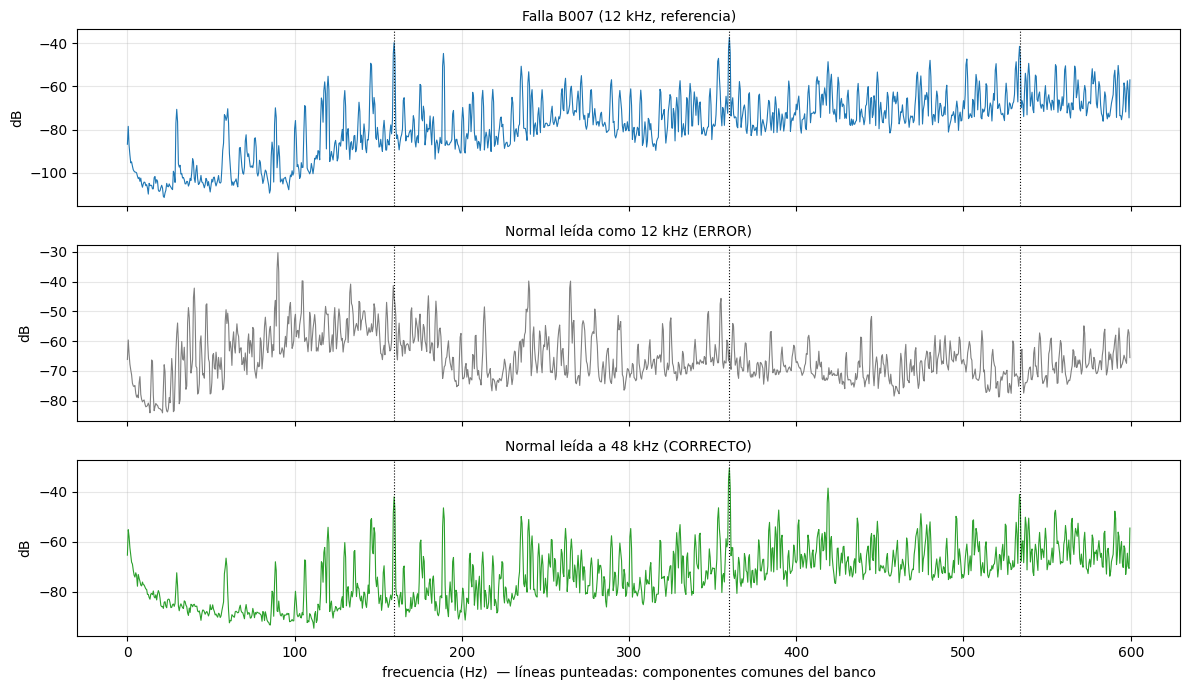

muestras: Normal original 483,903 vs falla 121,410 (misma duración ~10 s => Normal a 48 kHz)


In [9]:
import scipy.io as sio
m = sio.loadmat(cfg.root / "Normal" / "98_Normal_1.mat"); raw = m["X098_DE_time"].ravel()
ref, _, _ = load_signal(cfg, "B007", 1)
def spec(x, fs): f, p = welch(x - x.mean(), fs=fs, nperseg=fs * 2); k = f < 600; return f[k], 10 * np.log10(p[k])
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for a, (x, fs, lab, col) in zip(ax, [(ref, 12000, "Falla B007 (12 kHz, referencia)", COLORS["B"]),
                                     (raw, 12000, "Normal leída como 12 kHz (ERROR)", "gray"),
                                     (raw, 48000, "Normal leída a 48 kHz (CORRECTO)", COLORS["Normal"])]):
    f, p = spec(x, fs); a.plot(f, p, color=col, lw=0.8); a.set_title(lab, fontsize=10); a.set_ylabel("dB")
    for l in (159.5, 360.0, 533.5): a.axvline(l, color="k", ls=":", lw=0.8)
ax[-1].set_xlabel("frecuencia (Hz)  — líneas punteadas: componentes comunes del banco")
plt.tight_layout(); plt.show()
print(f"muestras: Normal original {len(raw):,} vs falla {len(ref):,} (misma duración ~10 s => Normal a 48 kHz)")

**(b) Un archivo duplicado.** `99_Normal_2.mat` trae dos señales: la suya (`X099`) y una copia de la carga 1 (`X098`). El código tomaba la primera y la carga 2 quedaba igual a la carga 1. Ahora se elige la variable cuyo número coincide con el del archivo.

In [10]:
m99 = sio.loadmat(cfg.root / "Normal" / "99_Normal_2.mat")
print("variables en 99_Normal_2.mat:", [k for k in m99 if not k.startswith("__")])
print("¿X098 dentro de 99 es igual a la carga 1?", np.array_equal(m99["X098_DE_time"], m["X098_DE_time"]))

variables en 99_Normal_2.mat: ['ans', 'X098_DE_time', 'X098_FE_time', 'X099_DE_time', 'X099_FE_time']
¿X098 dentro de 99 es igual a la carga 1? True


## 6. De señales a ejemplos de entrenamiento

Cada grabación de ~10 s se corta en **ventanas de 2048 muestras (0.17 s ≈ 5 vueltas del eje)**. Cada ventana es un ejemplo con su etiqueta (una de las 10 clases) y se normaliza (media 0, desviación 1).

La partición evita la **fuga de datos**:
- **Train:** cargas 0, 1 y 2 HP, el 80 % inicial de cada grabación (ventanas con paso de 512: se solapan entre sí, pero solo dentro de train).
- **Validación:** el 20 % final de esas grabaciones (sin solape con train). Sirve para elegir la mejor época.
- **Test:** la carga de **3 HP completa**, nunca vista. Es el examen final del modelo.

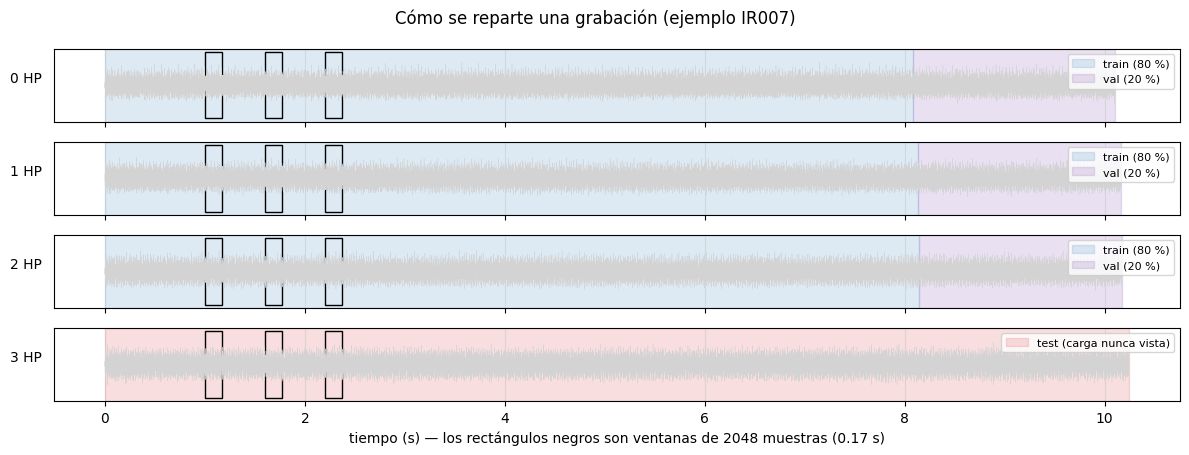

In [11]:
fig, axes = plt.subplots(4, 1, figsize=(12, 4.6), sharex=True)
for ax, load in zip(axes, range(4)):
    x, _, _ = load_signal(cfg, "IR007", load); t = np.arange(len(x)) / FS; cut = int(len(x) * (1 - cfg.val_frac))
    ax.plot(t, x, color="lightgray", lw=0.3)
    if load in cfg.train_loads:
        ax.axvspan(0, cut / FS, color="tab:blue", alpha=0.15, label="train (80 %)"); ax.axvspan(cut / FS, t[-1], color="tab:purple", alpha=0.2, label="val (20 %)")
    else:
        ax.axvspan(0, t[-1], color="tab:red", alpha=0.15, label="test (carga nunca vista)")
    for k in range(3):                                             # ejemplos de ventanas
        s = (1.0 + k * 0.6) * FS; ax.add_patch(Rectangle((s / FS, -2.5), cfg.win / FS, 5, fill=False, ec="k", lw=1))
    ax.set_ylabel(f"{load} HP", rotation=0, labelpad=20); ax.set_yticks([]); ax.legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("tiempo (s) — los rectángulos negros son ventanas de 2048 muestras (0.17 s)")
plt.suptitle("Cómo se reparte una grabación (ejemplo IR007)"); plt.tight_layout(); plt.show()

### El desbalance (a propósito)

En planta casi todo es "máquina sana" y las fallas graves son rarísimas. Para simularlo, en **train** se dejan solo el 30 %, 10 % y 3 % de las ventanas de las fallas leves, medias y graves. Validación y test quedan completos para medir con justicia. Las clases escasas son las que el **modelo de difusión** debe completar con ejemplos sintéticos.

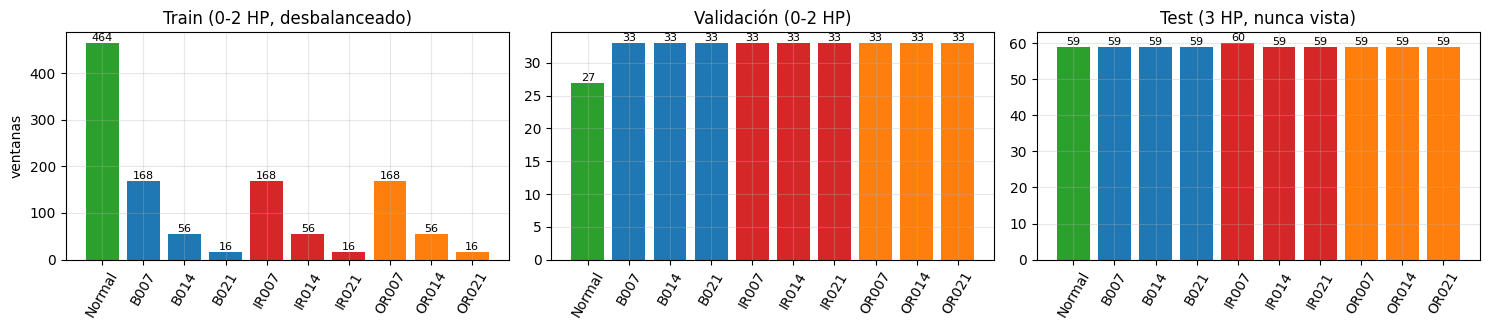

,Normal,B007,B014,B021,IR007,IR014,IR021,OR007,OR014,OR021
train,464,168,56,16,168,56,16,168,56,16
val,27,33,33,33,33,33,33,33,33,33
test,59,59,59,59,60,59,59,59,59,59


In [12]:
splits = build_split(cfg)
cnt = pd.DataFrame({k: np.bincount(v[1].numpy(), minlength=len(CLASSES)) for k, v in splits.items()}, index=CLASSES)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, k, title in zip(axes, ["train", "val", "test"], ["Train (0-2 HP, desbalanceado)", "Validación (0-2 HP)", "Test (3 HP, nunca vista)"]):
    ax.bar(CLASSES, cnt[k], color=[color(c) for c in CLASSES]); ax.set_title(title); ax.tick_params(axis="x", rotation=60)
    for i, v in enumerate(cnt[k]): ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
axes[0].set_ylabel("ventanas"); plt.tight_layout(); plt.show()
display(cnt.T)

## 7. ¿Qué "ve" cada modelo?

La misma ventana de 0.17 s se presenta de tres formas:
- **CNN 1D:** la señal cruda (2048 números).
- **CNN 2D:** un **espectrograma** (STFT): qué frecuencias suenan en cada instante, como una imagen.
- **AST (Transformer):** un **espectrograma mel** a 16 kHz (como el audio con el que se preentrenó en AudioSet), cortado en parches de 16×16 que el Transformer trata como "palabras".

/usr/local/lib/python3.13/dist-packages/torchaudio/functional/functional.py:581: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (128) may be set too high. Or, the value for `n_freqs` (257) may be set too low.
  warnings.warn(


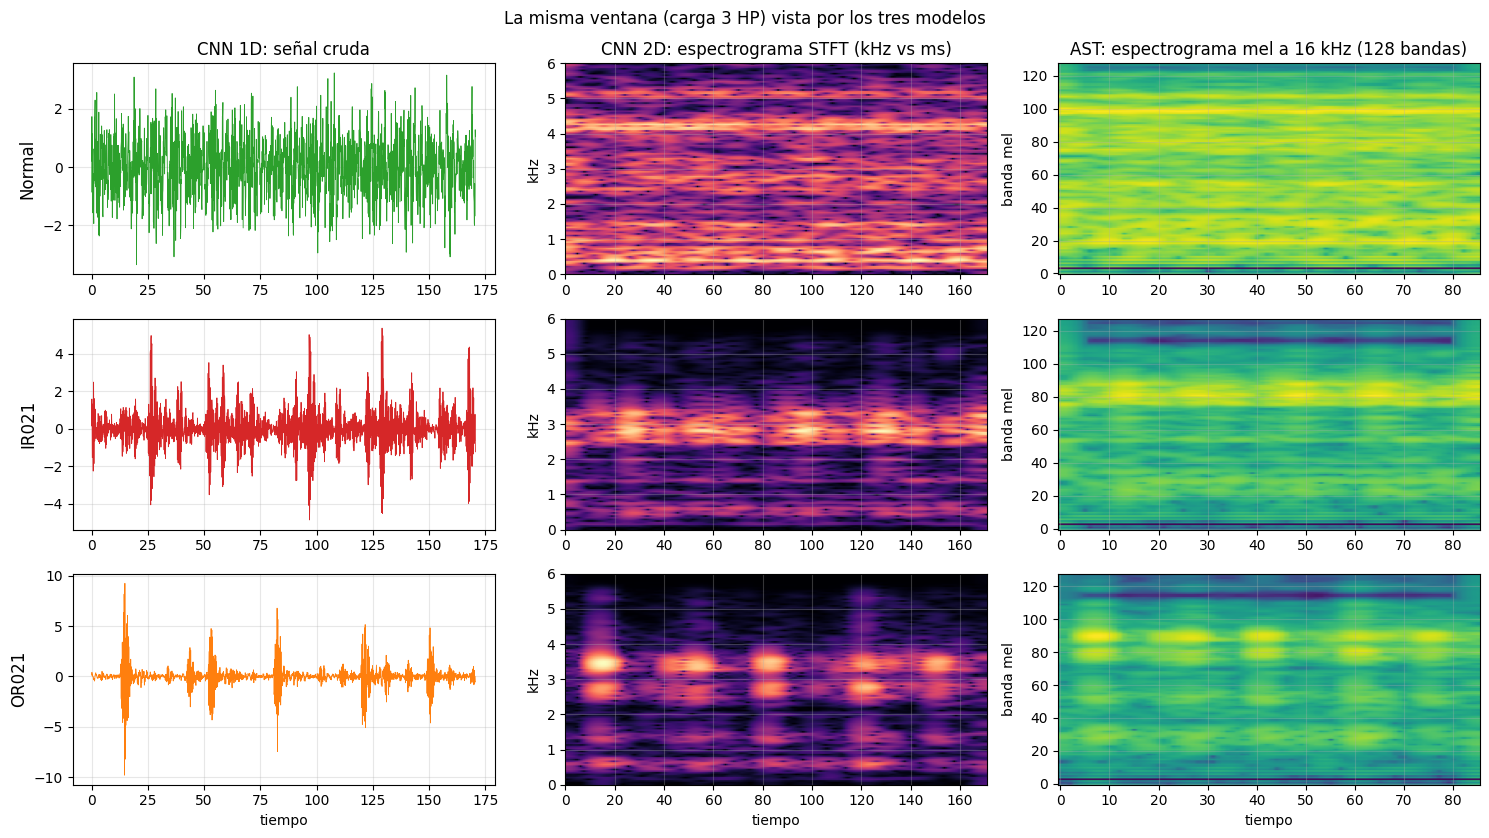

In [13]:
stft = STFTFrontend()
ast_mel = torchaudio.transforms.MelSpectrogram(sample_rate=16000, n_fft=512, win_length=400, hop_length=32, n_mels=128, f_min=20.0)
to16 = torchaudio.transforms.Resample(FS, 16000)
fig, axes = plt.subplots(3, 3, figsize=(15, 8.5))
for row, c in enumerate(["Normal", "IR021", "OR021"]):
    x, _, _ = load_signal(cfg, c, 3); w = torch.from_numpy(zscore(make_windows(x, cfg.win, cfg.win)[5:6]))
    axes[row, 0].plot(np.arange(cfg.win) / FS * 1000, w[0], color=color(c), lw=0.6); axes[row, 0].set_ylabel(c, fontsize=12)
    S = stft(w)[0, 0].numpy(); axes[row, 1].imshow(S, aspect="auto", origin="lower", extent=[0, 171, 0, FS / 2000], cmap="magma")
    M = torch.log(ast_mel(to16(w)) + 1e-6)[0].numpy(); axes[row, 2].imshow(M, aspect="auto", origin="lower", cmap="viridis")
axes[0, 0].set_title("CNN 1D: señal cruda"); axes[0, 1].set_title("CNN 2D: espectrograma STFT (kHz vs ms)"); axes[0, 2].set_title("AST: espectrograma mel a 16 kHz (128 bandas)")
for a in axes[-1]: a.set_xlabel("tiempo")
for a in axes[:, 1]: a.set_ylabel("kHz")
for a in axes[:, 2]: a.set_ylabel("banda mel")
plt.suptitle("La misma ventana (carga 3 HP) vista por los tres modelos"); plt.tight_layout(); plt.show()

En el espectrograma de las fallas se ven **franjas verticales periódicas**: son los golpes del defecto, repetidos a BPFI o BPFO. En el mel del AST, las bandas superiores (por encima de 6 kHz, aprox. las bandas 115 a 128) casi no tienen información: la señal original solo llega hasta 6 kHz (la mitad de 12 kHz) y lo que se ve ahí es fuga de la ventana, no vibración real.

## 8. Robustez: la misma señal con ruido

En planta hay ruido de otras máquinas. Por eso además del test limpio evaluamos con ruido blanco a **10 dB** (la señal es ~3 veces más fuerte que el ruido) y **0 dB** (señal y ruido igual de fuertes).

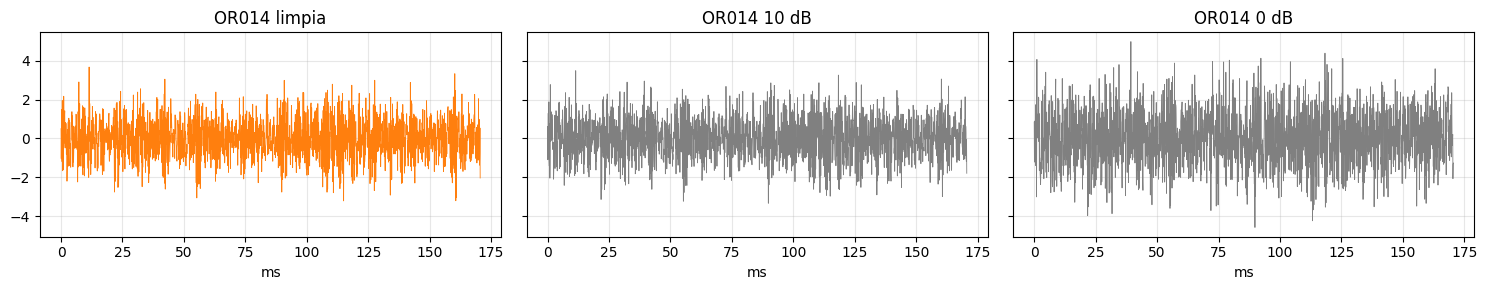

In [14]:
x, _, _ = load_signal(cfg, "OR014", 3); w = torch.from_numpy(zscore(make_windows(x, cfg.win, cfg.win)[3:4])); t = np.arange(cfg.win) / FS * 1000
fig, axes = plt.subplots(1, 3, figsize=(15, 3), sharey=True)
for ax, (lab, s) in zip(axes, [("limpia", None), ("10 dB", 10), ("0 dB", 0)]):
    y = w if s is None else add_noise(w, s); ax.plot(t, y[0], lw=0.6, color=COLORS["OR"] if s is None else "gray"); ax.set_title(f"OR014 {lab}"); ax.set_xlabel("ms")
plt.tight_layout(); plt.show()

## Resumen

| Qué | Valor |
|---|---|
| Fuente | CWRU Bearing Data Center (uso académico), espejo `s-whynot/CWRU-dataset` |
| Señal | Vibración del lado de accionamiento, 12 kHz (Normal remuestreada desde 48 kHz) |
| Clases | 10: Normal + {Bola, Pista interna, Pista externa} × {0.007, 0.014, 0.021 in} |
| Archivos | 40 (10 clases × 4 cargas), ~10 s cada uno |
| Ejemplo | ventana de 2048 muestras (0.17 s), normalizada |
| Partición | train 0-2 HP (80 % inicial, desbalanceado 30/10/3 %), val 0-2 HP (20 % final), test 3 HP |
| Física | BPFO = 3.585 f_r, BPFI = 5.415 f_r, BSF = 2.357 f_r |

Siguiente notebook: `01_pipeline_colab.ipynb` (entrenamiento de los 3 modelos × 3 aumentos y resultados).